In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale'].copy()
df['Area'] = df['Area Size']
df.loc[df['Area Type'] == 'Kanal', 'Area'] = df['Area Size'] * 20
df = df[(df['Area'] > 0) & (df['price'] > 0)]
df = df[(df['Area'] < df['Area'].quantile(0.99)) & (df['price'] < df['price'].quantile(0.99))]

In [3]:
X = df[['Area', 'price']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

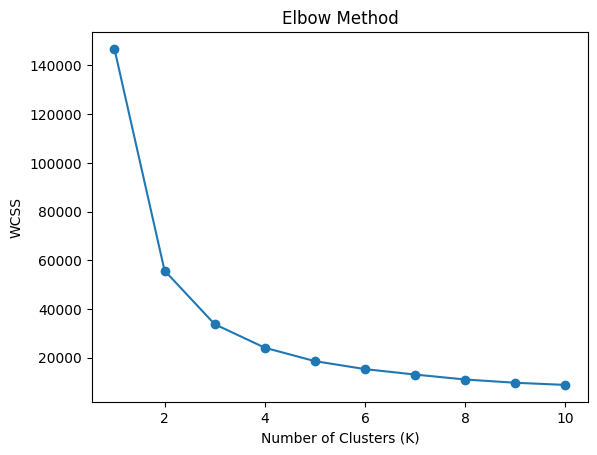

In [4]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method');plt.show()

In [5]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area', 'price']].mean())

Cluster
0    20115
1     2868
2    10129
3    40284
Name: count, dtype: int64
              Area         price
Cluster                         
0         9.742516  2.350153e+07
1        30.025384  1.228344e+08
2        19.652917  5.036213e+07
3         4.545686  8.456768e+06


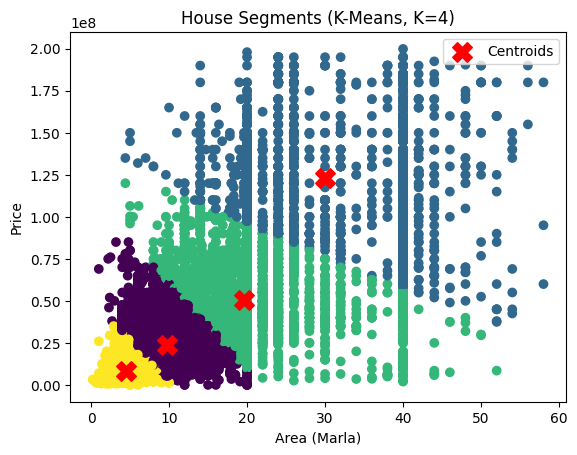

In [10]:
plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Area (Marla)')
plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)')
plt.legend()
plt.show()

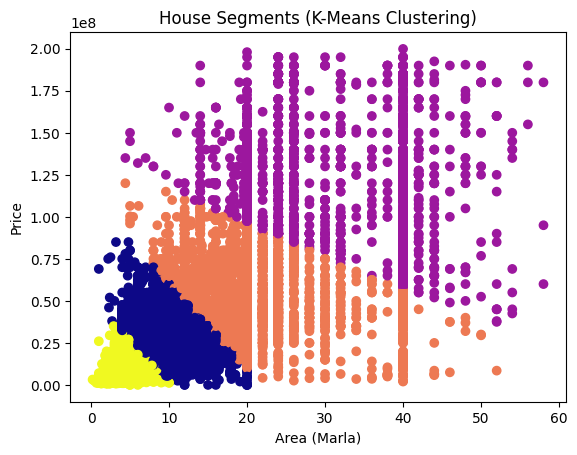

In [12]:
plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='plasma')
plt.xlabel('Area (Marla)')
plt.ylabel('Price')
plt.title('House Segments (K-Means Clustering)')
plt.show()